# **차원 축소**

차원 축소 알고리즘인 PCA, LDA, SVD, NMF에 대해서 알아보기

차원 축소: 매우 많은 피처로 구성된 다차원 데이터 세트의 차원을 축소해 새로운 차워의 데이터 세트를 생성하는 것이다
- 차원이 증가할수록 데이터 포인트 간의 거리가 기하급수적으로 멀어지게 되고, 희소(sparse)한 구조를 가지게 된다
- 수백 개 이상의 피처로 구성된 데이터 세트의 경우 상대적으로 적은 차원에서 학습된 모델보다 예측 신뢰도가 떨어진다
- 피처가 많을 경우 개별 피처 간에 상관관계가 높을 가능성이 크다
  - 선형 회귀와 같은 선형 모델에서는 입력 변수 간의 상관관계가 높을 경우 이로 인한 다중 공선성 문제로 모델의 예측 성능이 저하된다

3차원 이하의 차원 축소를 통해서 시각적으로 데이터를 압축해서
표현할 수 있다

차원 축소
- 피처 선택(feature selection)
  - 특성 선택은 말 그대로 특정 피처에 종속성이 강한 불필요한 피처는 아예 제거
  - 데이터의 특징을 잘 나타내는 주요 피처만 선택하는 것
- 피처 추출(feature extraction)
  - 기존 피처를 저차원의 중요 피처로 압축해서 추출하는 것

# PCA(Principal Component Analysis))

: 여러 변수 간에 존재하는 상관관계를 이용해 이를 대표하는 주성분(Principal Component)을 추출해 차워을 축소하는 기법

- 기존 데이터의 정보 유실이 최소화를 위해 PCA는 가장 높은 분산을 가지는 데이터의 축을 찾아 이 축으로 차원을 축소하는데, 이것이 PCA의 주성분이 된다
  - 분산이 데이터의 특성을 가장 잘 나타내는 것으로 간주

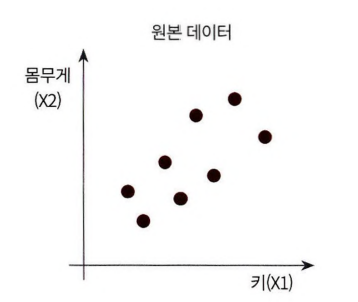

==> 2개의 피처를 한 개의 주성분을 가진 데이터 세트로 차원 축소

: 데이터 변동성이 가장 큰 방향으로 축을 생성하고, 새롭게 생성된 축으로 데이터를 투영하는 방식

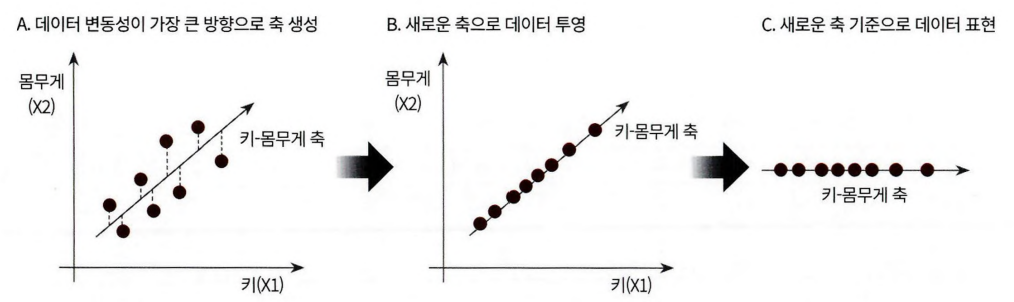

PCA는 제일 먼저 가장 큰 데이터 변동성(Variance)을 기반으로 첫 번째 벡터 축을 생성하고, 두 번째
축은 이 벡터 축에 직각이 되는 벡터(직교 벡터)를 축으로 한다

세 번째 축은 다시 두 번째 축과 직각
이 되는 벡터를 설정하는 방식으로 축을 생성한다


--> 이렇게 생성된 벡터 축에 원본 데이터를 투영하면
벡터 축의 개수만큼의 차원으로 원본 데이터가 차원 축소된다

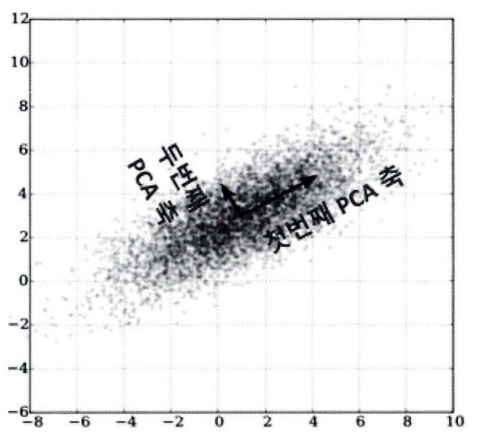

** PCA, 주성분 분석은 이처럼 원본 데이터의 피처 개수에 비해 매우 작은 주성분으로 원본 데이터의
총 변동성을 대부분 설명할 수 있는 분석법 **

<선형대수 관점>
- 입력 데이터의 공분산 행렬(Covariance Matrix)을 고유값 분해하고, 이렇게 구한 고유벡터에 입력 데이터를 선형 변환
- 이 고유벡터가 PCA의 주성분 벡터로서 입력 데이터의 분산이 큰 방향을 나타냄
  - 고윳값(eigenvalue)은 바로 이 고유벡터의 크
기를 나타내며, 동시에 입력 데이터의 분산을 나타냄

선형 변환: 특정 벡터에 행렬 A를 곱해 새로운 벡터로 변환하는 것을 의미
- 특정 벡터를 하나의 공간에서 다른 공간으로 투영하는 개념 = 이 행렬을 바로 공간으로 가정

공분산 행렬: 정방행렬(Square Matrix)이며 대칭행렬(Symmetric Matrix)
- 정방행렬은 열과 행이 같은 행렬을 지칭하는데, 정방행렬 중에서 대각 원소를 중심으로 원소 값이 대칭되는 행렬
- 개별 분산값을 대각 원소로 하는 대칭행렬
  - 대칭행렬은 항상 고유벡터를 직교행렬(orthogonal matrix)로, 고유값을 정방 행렬로 대각화할 수 있다

*** 입력 데이터의 공분산 행렬이 고유벡터와 고유값으로 분해될 수 있으며, 이렇게 분해된 고유벡터를 이용해 입력 데이터를 선형 변환하는 방식이 PCA ***

[ PCA 수행 단계 ]
- 입력 데이터 세트의 공분산 행렬 사용
- 공분산 행렬의 고유벡터와 고유값 계산
- 고유값이 가장 큰 순으로 K개(PCA 변환 차수만큼)만큼 고유벡터 추출
- 고유값이 가장 큰 순으로 추출된 고유벡터를 이용해 새롭게 입력 데이터 변환

[ 붓꽃(Iris) 데이터 세트는 sepal length, sepal width, petal length, petal width의 4개의 속성으로 되어 있는데, 이 4개의 속성을 2개의 PCA 차원으로 압축해 원래 데이터 세트와 압축된 데이터 세트가 어떻게 달라졌는지 확인해보기 ]

In [4]:
from sklearn.datasets import load_iris
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
iris = load_iris()

# 넘파이 데이터 세트를 판다스 DataFrame으로 변환
columns = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
irisDF = pd.DataFrame(iris.data, columns=columns)
irisDF['target']=iris.target
irisDF.head(3)


,sepal_length,sepal_width,petal_length,petal_width,target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0


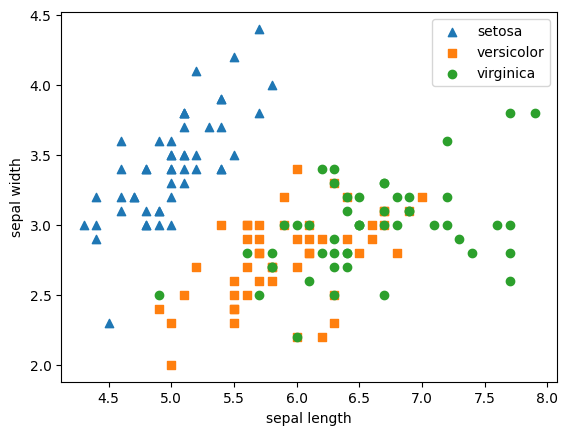

In [5]:
#setosa는 세모, versicolor는 네모, virginica는 동그라미로 표현
markers=['^', 's', 'o']
#setosa의 target 값은 0, versicolor는 1, virginica는 2. 각 target별로 다른 모양으로 산점도로 표시
for i, marker in enumerate(markers):
  x_axis_data = irisDF [irisDF ['target']==i] ['sepal_length']
  y_axis_data = irisDF [irisDF ['target']==i] ['sepal_width']
  pit.scatter(x_axis_data, y_axis_data, marker=marker, label=iris.target_names[i])
plt.legend()
plt.xlabel('sepal length')
plt.ylabel('sepal width')
plt.show()


--> Setosa 품종의 경우 sepal width가 3.0보다 크고, sepal length가 6.0 이하인 곳에 일정하게 분포

In [6]:
## PCA로 4개 속성을 2개로 압축한 뒤 앞의 예제와 비슷하게 2개의 PCA 속성으로 붓꽃 데이터의 품종 분포를 2차원으로 시각화


from sklearn.preprocessing import StandardScaler
# Target 값을 제외한 모든 속성 값을 StandardScaler를 이용해 표준 정규 분포를 가지는 값들로 변환
iris_scaled = StandardScaler().fit_transform(irisDF.iloc[:, :-1])

In [7]:
from sklearn.decomposition import PCA
pea = PCA(n_components=2)
# fit()과 transformO을 호출해 PCA 변환 데이터 반환
pea.fit(iris_scaled)
iris_pca = pea.transform(iris_scaled)
print(iris_pca.shape)


(150, 2)


In [8]:
# PCA 변환된 데이터의 칼럼명을 각각 pca_component_1, pca_component_2로 명명
pca_columns=['pca_component_1','pca_component_2']
irisDF_pca = pd.DataFrame(iris_pca, columns=pca_columns)
irisDF_pca['target']=iris.target
irisDF_pca.head(3)

,pca_component_1,pca_component_2,target
0,-2.264703,0.480027,0
1,-2.080961,-0.674134,0
2,-2.364229,-0.341908,0


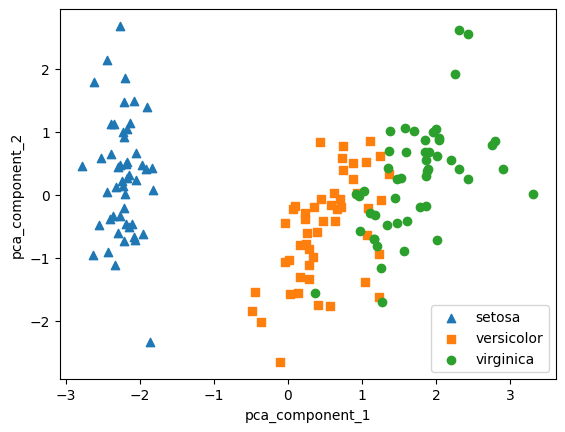

In [10]:
# setosa를 세모, versicolor를 네모, virginica를 동그라미로 표시
markers=['^', 's', 'o']

# pca_component_1 을 x축, pc_component_2를 y축으로 scatter plot 수행
for i, marker in enumerate(markers):
  x_axis_data = irisDF_pca[irisDF_pca['target']==i]['pca_component_1']
  y_axis_data = irisDF_pca[irisDF_pca['target']==i]['pca_component_2']
  plt.scatter(x_axis_data, y_axis_data, marker=marker,label=iris.target_names[i])
pit.legend()
plt.xlabel('pca_component_1')
plt.ylabel('pca_component_2')
plt.show()

--> PCA로 변환한 후에도 pca_component_1 축을 기반으로 Setosa 품종은 명확하게 구분이 가능합니
다. Versicolor와 Virginica는 pca_component_1  축을 기반으로 서로 겹치는 부분이 일부 존재하지만, 비교적 잘 구분됐다.

In [11]:
print(pea.explained_variance_ratio_)

[0.72962445 0.22850762]


--> 첫 번째 PCA 변환 요소인 pca_component_l이 전체 변동성의 약 72.9%를 차지하며, 두 번째인
pca_component_2가 약 22.8W 차지합니다. 따라서 PCA를 2개 요소로만 변환해도 원본 데이터의 변동성을 95% 설명할 수 있다.

[ 원본 붓꽃 데이터 세트와 PCA로 변환된 데이터 세트
에 각각 분류를 적용한 후 결과를 비교 ]

In [13]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
import numpy as np

rcf = RandomForestClassifier(random_state=156)
scores = cross_val_score(rcf, iris.data, iris.target,scoring='accuracy', cv=3)
print('원본 데이터 교차 검증 개별 정확도:', scores)
print('원본 데이터 평균 정확도:', np. mean (scores))

원본 데이터 교차 검증 개별 정확도: [0.98 0.94 0.96]
원본 데이터 평균 정확도: 0.96


In [14]:
pca_X = irisDF_pca[['pca_component_1', 'pca_component_2']]
scores_pca = cross_val_score(rcf, pca_X, iris.target, scoring='accuracy', cv=3 )
print('PCA 변환 데이터 교차 검증 개별 정확도:', scores_pca)
print( 'PCA 변환 데이터 평균 정확도:', np.mean(scores_pca))

PCA 변환 데이터 교차 검증 개별 정확도: [0.88 0.88 0.88]
PCA 변환 데이터 평균 정확도: 0.88


--> 4개의 속성이 2개의 변환 속성으로 감소하면서 예측 성능의 정확도가 원본 데이터 대비 약 8% 하락했습니다. 8%의 정확도 하락은 비교적 큰 성능 수치의 감소지만, 4개의 속성이 2개로, 속성 개수가 50% 감소한 것을 고려한다면 PCA 변환 후에도 원본 데이터의 특성을 상당 부분 유지하고 있음을 알 수 있다

In [15]:
# header로 의미 없는 첫 행 제거, 그이로 기존 id 제거
import pandas as pd
df = pd.read_excel('pca_credit_card.xls', header=1, sheet_name='Data').iloc[0:, 1:]
print(df.shape)
df.head(3)

(30000, 24)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0


In [19]:
df.rename(columns={'PAY_0':'PAYJ', 'default payment next month':'default'}, inplace=True)
y_target = df['default']
X_features = df.drop('default', axis=1)

<Axes: >

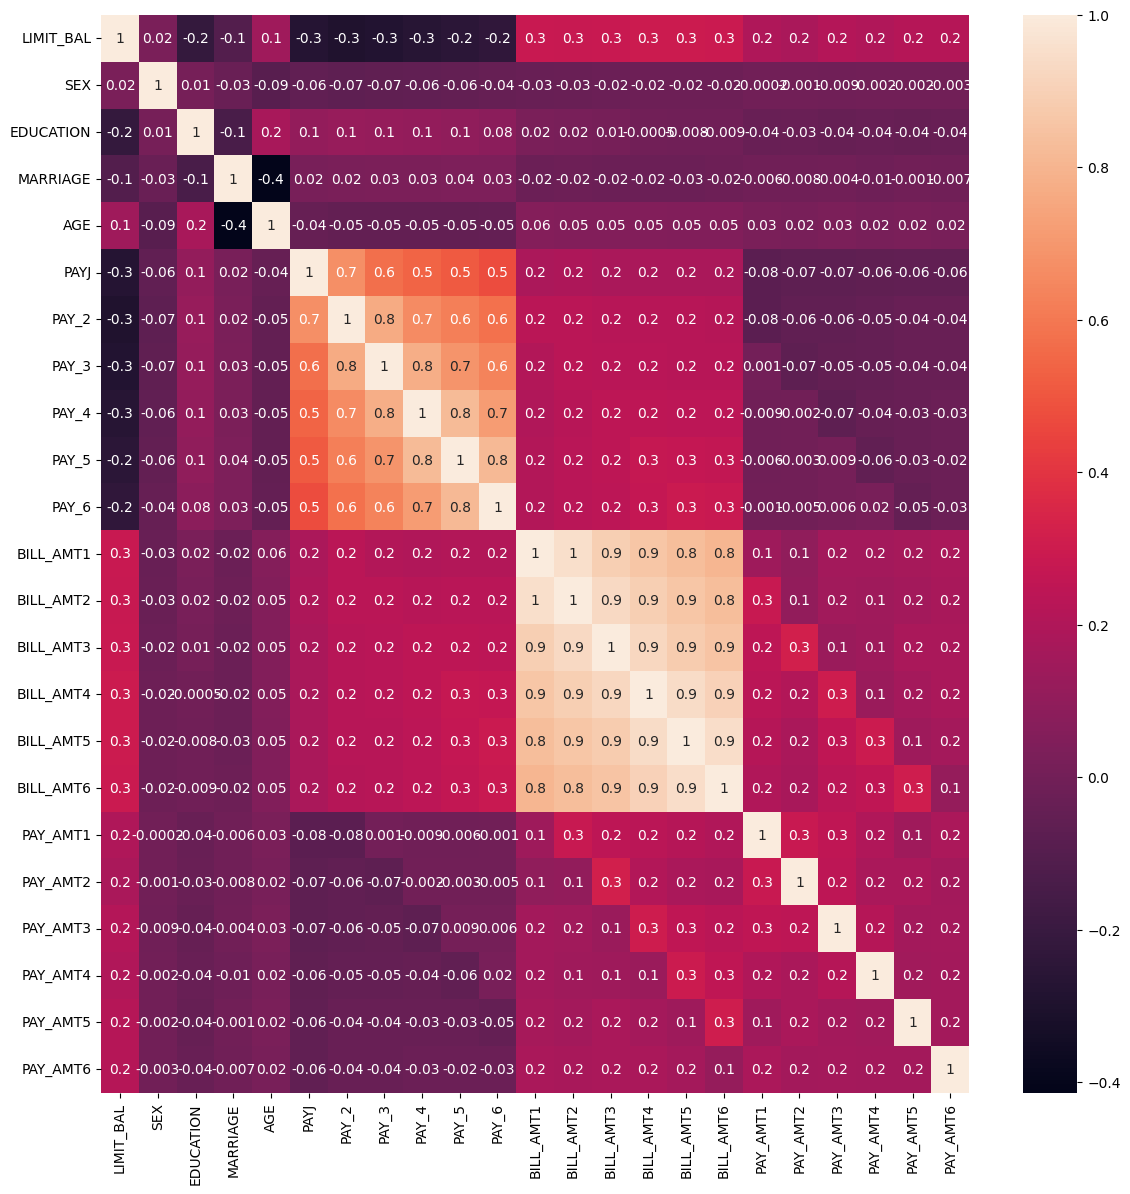

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

corr = X_features.corr()
plt.figure(figsize=(14, 14))
sns.heatmap(corr, annot=True, fmt='.1g')

--> BILL_AMT1~BILL_AMT6 6개 속성끼리의 상관도가 대부분 0.9 이상으로 매우 높다

In [22]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# BILL_AMT1 ~ BILL_AMT6까지 6개의 속성명 생성
cols_bill = ['BILL_AMT'+str(i) for i in range(1, 7)]
print('대상 속성명:', cols_bill)

# 2개의 PCA 속성을 가진 PCA 객체 생성하고, explained_variance_ratio_ 계산을 위해 fit( ) 호출
scaler = StandardScaler()
df_cols_scaled = scaler.fit_transform(X_features[cols_bill])
pca = PCA(n_components=2)
pca.fit(df_cols_scaled)
print('PCA Component 별 변동성:', pca.explained_variance_ratio_)

대상 속성명: ['BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6']
PCA Component 별 변동성: [0.90555253 0.0509867 ]


--> 단 2개의 PCA 컴포넌트만으로도 6개 속성의 변동성을 약 95% 이상 설명할 수 있으며 특히 첫 번째
PCA 축으로 90%의 변동성을 수용할 정도로 이 6개 속성의 상관도가 매우 높다

In [58]:
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

rcf = RandomForestClassifier(n_estimators=300, random_state=156)
scores = cross_val_score(rcf, X_features, y_target, scoring='accuracy', cv=3)
print('CV=3 인 경우의 개별 Fold세트별 정확도:', scores)
print('평균 정확도:{0:.4f}'.format(np.mean(scores)))

CV=3 인 경우의 개별 Fold세트별 정확도: [0.8083 0.8196 0.8232]
평균 정확도:0.8170


In [27]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 원본 데이터 세트에 먼저 StandardScaler 적용
scaler = StandardScaler()
df_scaled = scaler.fit_transform(X_features)

# 6개의 컴포넌트를 가진 PCA 변환을 수행하고 cross_val_score( )로 분류 예측 수행.
pca = PCA(n_components=6)
df_pca = pea.fit_transform(df_scaled)
scores_pca = cross_val_score(rcf, df_pca, y_target, scoring='accuracy', cv=3)

print('CV=3 인 경우의 PCA 변환된 개별 Fold 세트별 정확도:', scores_pca)
print('PCA 변환 데이터 세트 평균 정확도:{0:.4f}'.format(np.mean(scores_pca)))

CV=3 인 경우의 PCA 변환된 개별 Fold 세트별 정확도: [0.7699 0.7841 0.7889]
PCA 변환 데이터 세트 평균 정확도:0.7810


--> 전체 23개 속성의 약 1/4 수준인 6개의 PCA 컴포넌트만으로도 원본 데이터를 기반으로 한 분류 예측 결과보다 약 1~2% 정도의 예측 성능 저하만 발생했다

# LDA(Linear Discriminant Analysis)

LDA(Linear Discriminant Analysis)는 선형 판별 분석법으로 불리며, PCA와 매우 유사
- PCA와유사하게 입력 데이터 세트를 저차원 공간에 투영해 차원을 축소하는 기법이지만, 중요한 차이는 LDA는 지도학습의 분류(Classification)에서 사용하기 쉽도록 개별 클래스를 분별할 수 있는 기준을 최대한 유지하면서 차원을 축소
- PCA는 입력 데이터의 변동성의 가장 큰 축을 찾았지만, LDA는 입력 데이터의 결정 값 클래스를 최대한으로 분리할 수 있는 축을 찾는다



특정 공간상에서 클래스 분리를 최대화하는 축을 찾기 위해 클래스 간 분산(between-class scatter)과 클래스 내부 분산(within-class scatter)의 비율을 최대화하는 방식으로 차원을 축소한다
- 클래스 간분산은 최대한 크게 가져가고, 클래스 내부의 분산은 최대한 작게 가져가는 방식

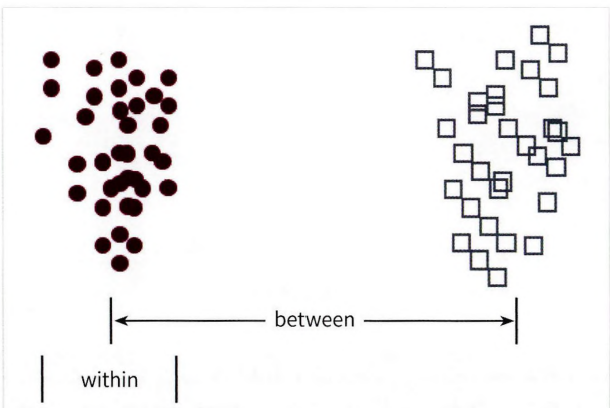

[ LDA 구하는 단계 ]

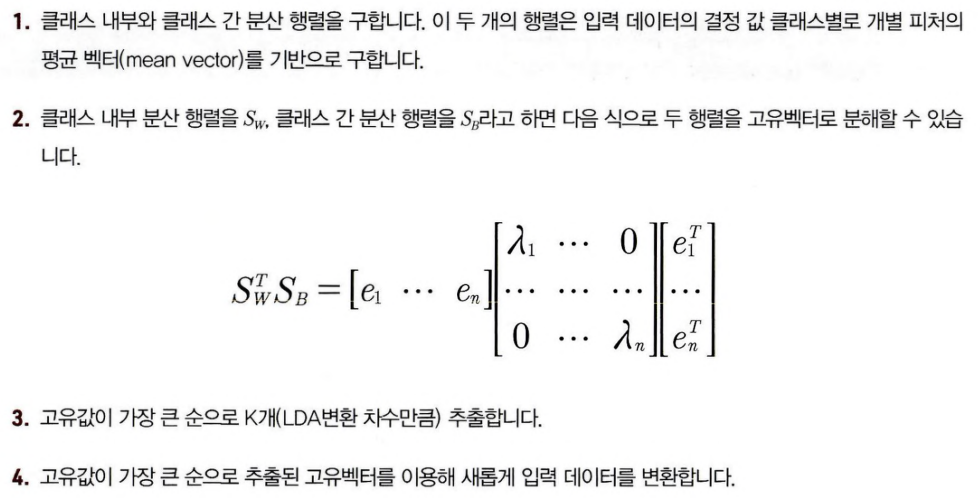

# 붓꽃 데이터 세트에 LDA 적용하기

In [30]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_iris
iris = load_iris()
iris_scaled = StandardScaler().fit_transform(iris.data)


In [32]:
lda = LinearDiscriminantAnalysis(n_components=2)
lda.fit(iris_scaled, iris.target)
iris_lda = lda.transform(iris_scaled)
print(iris_lda.shape)

(150, 2)


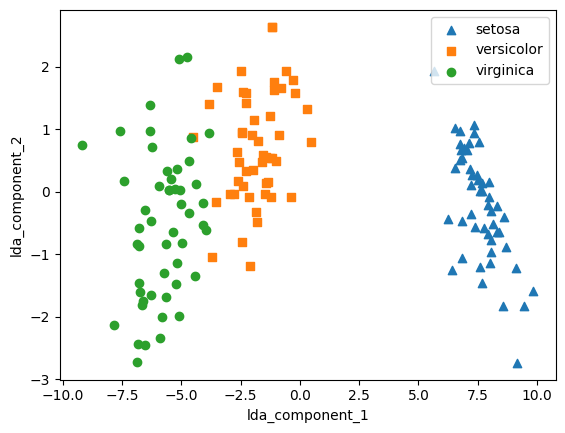

In [35]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

lda_columns=['lda_component_1', 'lda_component_2']
irisDF_lda = pd.DataFrame(iris_lda, columns=lda_columns)
irisDF_lda['target']=iris.target
#setosa는 세모, versicolor는 네모, virginica는 동그라미로 표현
markers=['^', 's', 'o']
#setosa의 target 값은 0, versicolor는 1, virginica는 2. 각 target별로 다른 모양으로 산점도로 표시
for i, marker in enumerate(markers):
  x_axis_data = irisDF_lda[irisDF_lda['target']==i]['lda_component_1']
  y_axis_data = irisDF_lda[irisDF_lda['target']==i]['lda_component_2']
  plt.scatter(x_axis_data, y_axis_data, marker=marker, label=iris.target_names[i])

plt.legend(loc='upper right')
plt.xlabel('lda_component_1')
plt.ylabel('lda_component_2')
plt.show()

# SVD(Singular Value Decomposition)


SVD 역시 PCA와 유사한 행렬 분해 기법을 이용한다

PCA의 경우 정방행렬(즉, 행과 열의 크기가
같은 행렬)만을 고유벡터로 분해할 수 있지만, SVD는 정방행렬뿐만 아니라 행과 열의 크기가 다른 행
렬에도 적용할 수 있다
- SVD는 m X n 크기의 행렬 方를 다음과 같이 분해하는 것을 의미



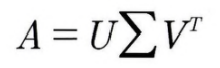

SVD는 특이값 분해로 불리며, 행렬 1/와 V에 속한 벡터는 특이벡터(singular vector)이며, 모든 특이
벡터는 서로 직교하는 성질을 가진다


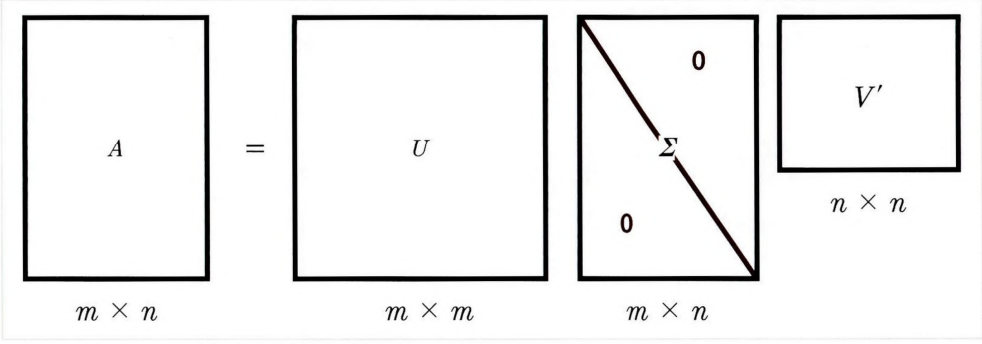

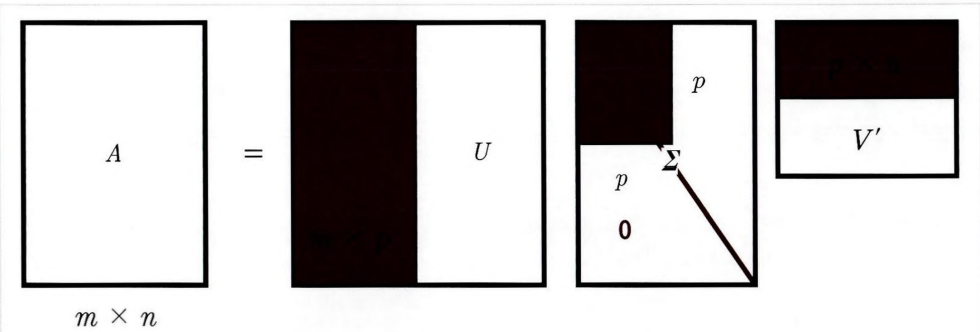

In [37]:
# 넘파이의 svd 모듈 임포트
import numpy as np
from numpy.linalg import svd

# 4X4 랜덤 행렬 a 생성
np.random.seed(121)
a = np.random.randn(4, 4)
print(np.round(a, 3))

[[-0.212 -0.285 -0.574 -0.44 ]
 [-0.33   1.184  1.615  0.367]
 [-0.014  0.63   1.71  -1.327]
 [ 0.402 -0.191  1.404 -1.969]]


In [39]:
U, Sigma, Vt = svd(a)
print(U.shape, Sigma.shape, Vt.shape)
print('ll matrix：\n', np.round(U, 3))
print('Sigma Value：\n', np.round(Sigma, 3))
print('V transpose matrix：\n', np.round(Vt, 3))

(4, 4) (4,) (4, 4)
ll matrix：
 [[-0.079 -0.318  0.867  0.376]
 [ 0.383  0.787  0.12   0.469]
 [ 0.656  0.022  0.357 -0.664]
 [ 0.645 -0.529 -0.328  0.444]]
Sigma Value：
 [3.423 2.023 0.463 0.079]
V transpose matrix：
 [[ 0.041  0.224  0.786 -0.574]
 [-0.2    0.562  0.37   0.712]
 [-0.778  0.395 -0.333 -0.357]
 [-0.593 -0.692  0.366  0.189]]


--> U 행렬이 4 x 4, Vt 행렬이 4 x 4로 반환됐고, Sigma의 경우는 1차원 행렬인 (4,)로 반환됐다

In [40]:
# Sigma를 다시 0을 포함한 대칭행렬로 변환
Sigmajnat = np.diag(Sigma)
a_ = np.dot(np.dot(U, Sigmajnat), Vt)
print(np.round(a_, 3))

[[-0.212 -0.285 -0.574 -0.44 ]
 [-0.33   1.184  1.615  0.367]
 [-0.014  0.63   1.71  -1.327]
 [ 0.402 -0.191  1.404 -1.969]]


In [43]:
a[2] = a[0] + a[1]
a[3] = a[0]
print(np.round(a, 3))

[[-0.212 -0.285 -0.574 -0.44 ]
 [-0.33   1.184  1.615  0.367]
 [-0.542  0.899  1.041 -0.073]
 [-0.212 -0.285 -0.574 -0.44 ]]


--> 이제 a 행렬은 이전과 다르게 로우 간 관계가 매우 높아졌다

In [44]:
# 다시 SVD를 수행해 Sigma 값 확인
U, Sigma, Vt = svd(a)
print(U.shape, Sigma.shape, Vt.shape)
print('Sigma Value：\n', np.round(Sigma, 3))

(4, 4) (4,) (4, 4)
Sigma Value：
 [2.663 0.807 0.    0.   ]


--> 이전과 차원은 같지만 Sigma 값 중 2개가 0으로 변했다.
- 선형 독립인 로우 벡터의 개수가 2개라는 의미

In [47]:
# U 행렬의 경우는 Sigma와 내적을 수행하므로 Sigma의 앞 2행에 대응되는 앞 2열만 추출
U_ = U[:, :2]
Sigma_ = np.diag(Sigma[:2])

# V 전치 행렬의 경우는 앞 2행만 추출
Vt_ = Vt[:2]
print(U_.shape, Sigma_.shape, Vt_.shape)

# U, Sigma, Vt의 내적을 수행하며, 다시 원본 행렬 복원
a_ = np.dot(np.dot(U_, Sigma_), Vt_)
print(np.round(a_, 3))

(4, 2) (2, 2) (2, 4)
[[-0.212 -0.285 -0.574 -0.44 ]
 [-0.33   1.184  1.615  0.367]
 [-0.542  0.899  1.041 -0.073]
 [-0.212 -0.285 -0.574 -0.44 ]]


[ Truncated SVD를 이용해 행렬을 분해 ]

In [49]:
import numpy as np
from scipy.sparse.linalg import svds
from scipy.linalg import svd

# 원본 행렬을 출력하고 SVD를 적용할 경우 U, Sigma, Vt의 차원 확인
np.random.seed(121)
matrix = np.random.random((6, 6))
print('원본 행렬:\n', matrix)
U, Sigma, Vt = svd(matrix, full_matrices=False)
print('\n분해 행렬 차원:', U.shape, Sigma.shape, Vt.shape)
print('\nSigma값 행렬:', Sigma)

# Truncated SVD로 Sigma 행렬의 특이값을 4개로 하여 Truncated SVD 수행
num_components = 4
U_tr, Sigma_tr, Vt_tr = svds(matrix, k=num_components)
print('\nTruncated SVD 분해 행렬 차원:', U_tr.shape, Sigma_tr.shape, Vt_tr.shape)
print('\nTruncated SVD Sigma값 행렬:', Sigma_tr)

# Truncated SVD로 분해 후 복원 행렬 계산
matrix_tr = np.dot(np.dot(U_tr, np.diag(Sigma_tr)), Vt_tr)
print('\nTruncated SVD로 분해 후 복원 행렬:\n', matrix_tr)

원본 행렬:
 [[0.11133083 0.21076757 0.23296249 0.15194456 0.83017814 0.40791941]
 [0.5557906  0.74552394 0.24849976 0.9686594  0.95268418 0.48984885]
 [0.01829731 0.85760612 0.40493829 0.62247394 0.29537149 0.92958852]
 [0.4056155  0.56730065 0.24575605 0.22573721 0.03827786 0.58098021]
 [0.82925331 0.77326256 0.94693849 0.73632338 0.67328275 0.74517176]
 [0.51161442 0.46920965 0.6439515  0.82081228 0.14548493 0.01806415]]

분해 행렬 차원: (6, 6) (6,) (6, 6)

Sigma값 행렬: [3.2535007  0.88116505 0.83865238 0.55463089 0.35834824 0.0349925 ]

Truncated SVD 분해 행렬 차원: (6, 4) (4,) (4, 6)

Truncated SVD Sigma값 행렬: [0.55463089 0.83865238 0.88116505 3.2535007 ]

Truncated SVD로 분해 후 복원 행렬:
 [[0.19222941 0.21792946 0.15951023 0.14084013 0.81641405 0.42533093]
 [0.44874275 0.72204422 0.34594106 0.99148577 0.96866325 0.4754868 ]
 [0.12656662 0.88860729 0.30625735 0.59517439 0.28036734 0.93961948]
 [0.23989012 0.51026588 0.39697353 0.27308905 0.05971563 0.57156395]
 [0.83806144 0.78847467 0.93868685 0.72673231 

--> 6x6 행렬을 SVD 분해하면 U, Sigma, Vt가 각각 (6, 6) (6,) (6, 6) 차원이지만, Truncated SVD의
n_components를 4로 설정해 U, Sigma, Vt를 (6, 4) (4,) (4, 6)로 각각 분해했다. Truncated
SVD로 분해된 행렬로 다시 복원할 경우 완벽하게 복원되지 않고 근사적으로 복원됨을 알 수 있다

# 사이킷런 TruncatedSVD 클래스를 이용한 변환

Text(0, 0.5, 'TruncatedSVD Component 2')

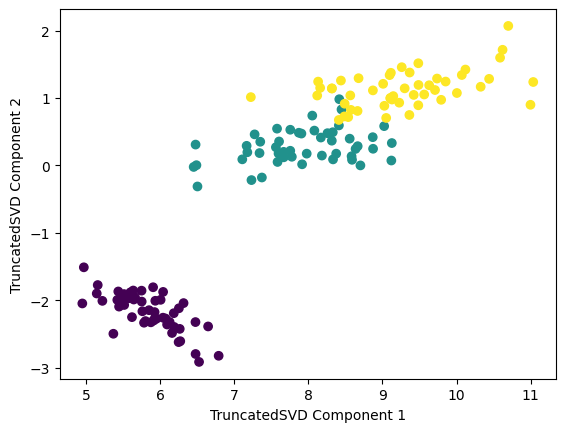

In [51]:
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.datasets import load_iris
import matplotlib.pyplot as plt
%matplotlib inline

iris = load_iris()
iris_ftrs = iris.data

# 2개의 주요 컴포넌트로 TruncatedSVD 변환
tsvd = TruncatedSVD(n_components=2)
tsvd.fit(iris_ftrs)
iris_tsvd = tsvd.transform(iris_ftrs)

# 산점도 2차원으로 TruncatedSVD 변환된 데이터 표현. 품종은 색깔로 구분
plt.scatter(x=iris_tsvd[:, 0], y=iris_tsvd[:, 1], c=iris.target)
plt.xlabel('TruncatedSVD Component 1')
plt.ylabel('TruncatedSVD Component 2')

In [55]:
# pea 객체를 다시 붓꽃 데이터(iris_scaled)로 학습시킵니다.
pea.fit(iris_scaled)
iris_pca = pea.transform(iris_scaled)

# 이제 두 모델의 components_ 차원이 (2, 4)로 일치하므로 정상 작동합니다.
print((iris_pca - iris_tsvd).mean())
print((pea.components_ - tsvd.components_).mean())

-3.71175913469594
0.09445103577591488


# NMF(Non-Negative Matrix Factorization)

NMF는 Truncated SVD와 같이 낮은 랭크를 통한 행렬 근사｛Low—Rank Approximation) 방식의
변형이다
- 원본 행렬 내의 모든 원소 값이 모두 양수(0 이상)라는 게 보장되면 다음과 같이
좀 더 간단하게 두 개의 기반 양수 행렬로 분해될 수 있는 기법을 지칭

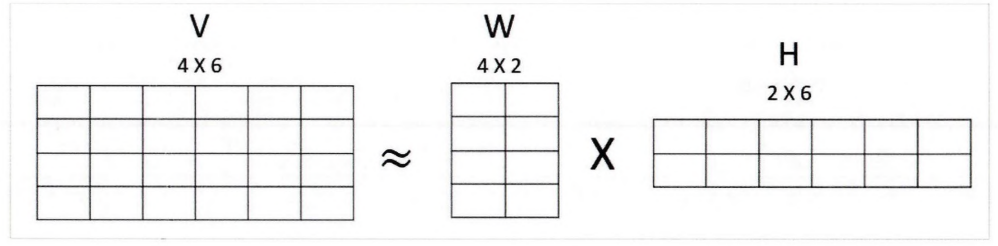

4 X 6 원본 행렬 V는 4 X 2 행렬 W와 2 X 6 행렬 日로 근사해 분해될 수 있다
- 행렬 분해（Matrix Factorization）는 일반적으로 SVD와 같은 행렬 분해 기법을 통칭하는 것
- 행렬 분해를 하게 되면 W 행렬과 H 행렬은 일반적으로 길고 가는 행렬 W（즉, 원본 행렬의 행 크기와 같고 열 크기 보다 작은 행렬）와 작고 넓은 행렬 H（원본 행렬의 행 크기보다 작고 열 크기와 같은 행렬）로 분해된다
- 분해된 행렬은 잠재 요소를 특성으로 가지게 된다

(분해 행렬 W는 원본 행에 대해서 이 잠재 요소의 값이 얼마나 되는지에 대응하며, 분해 행렬 日는 이 잠재 요소가 원본 열（즉, 원본 속성）로 어떻게 구성됐는지를 나타내는 행렬)

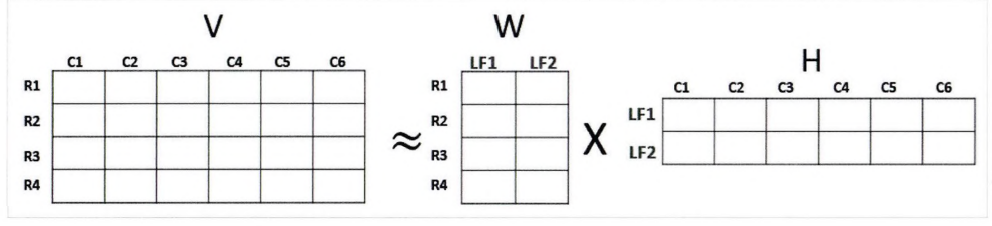

/usr/local/lib/python3.13/dist-packages/sklearn/decomposition/_nmf.py:1742: ConvergenceWarning: Maximum number of iterations 200 reached. Increase it to improve convergence.
  warnings.warn(


Text(0, 0.5, 'NMF Component 2')

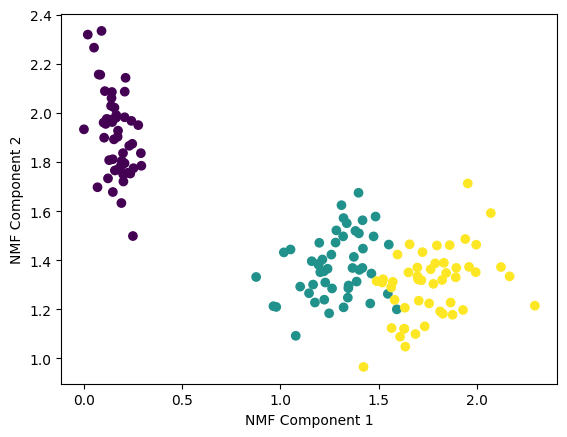

In [57]:
from sklearn.decomposition import NMF
from sklearn.datasets import load_iris
import matplotlib.pyplot as plt
%matplotlib inline

iris = load_iris()
iris_ftrs = iris.data

nmf = NMF(n_components=2, init='random', random_state=0)
nmf.fit(iris_ftrs)
iris_nmf = nmf.transform(iris_ftrs)

plt.scatter(x=iris_nmf[:, 0], y=iris_nmf[:, 1], c=iris.target)
plt.xlabel('NMF Component 1')
plt.ylabel('NMF Component 2')

## Summary

차원 축소의 의미
- 피처 수를 줄이는 것보다, 데이터를 잘 설명하는 잠재 요소를 뽑아내는 데 의미가 크다.
- 그래서 차원이 많은 이미지나 텍스트 데이터에 자주 쓰인다.


PCA (주성분 분석)
- 데이터 변동성이 가장 큰 축을 먼저 찾고, 그 축에 직각인 축을 원하는 차원 수만큼 이어서 찾는다.
- 공분산 행렬의 고유 벡터를 구하고, 데이터를 그 벡터에 투영(선형 변환)해 차원을 줄인다.


LDA (선형 판별 분석)
- 방식은 PCA와 비슷하다.
- 다만 변동성이 아니라 결정 값 클래스를 가장 잘 나누는 축을 찾는다.


SVD와 NMF
- 고차원 행렬을 저차원 행렬 두 개로 나누는 행렬 분해 기법이다.
- 분해하면서 잠재 요소를 뽑아내기 때문에 토픽 모델링과 추천 시스템에 많이 쓰인다.

*** 한 줄 요약: PCA는 분산을, LDA는 클래스 분리를 기준으로 축을 찾고, SVD와 NMF는 행렬을 분해해 잠재 요소를 뽑아낸다.